In [214]:
#CÉLULA 1
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Semente fixa obrigatoria
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
print('Ambiente configurado com sucesso!')

Ambiente configurado com sucesso!


In [215]:
#CÉLULA 2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Carregamento do arquivo original existente
CAMINHO_DADOS = 'dados/tabela_p4.csv'
df_bruto = pd.read_csv(CAMINHO_DADOS)

# 2. Pipeline de Tratamento da Etapa 1 (em memoria)
# Filtra apenas multas validas e remove outliers extremados (Percentil 99)
df = df_bruto[df_bruto['VAL_AUTO_INFRACAO'] > 0].copy()
limite_sup = df['VAL_AUTO_INFRACAO'].quantile(0.99)
df = df[df['VAL_AUTO_INFRACAO'] <= limite_sup].copy()

colunas_continuas = ['precip_mm', 'temp_media', 'umid_media']
colunas_categoricas = ['BIOMA', 'TP_PESSOA_INFRATOR', 'TIPO_ACAO']

# Imputacao de valores ausentes
for col in colunas_continuas:
  df[col] = df[col].fillna(df[col].median())

for col in colunas_categoricas:
  df[col] = df[col].fillna(df[col].mode()[0])

# 3. Criacao dos Alvos
y_reg = np.log1p(df['VAL_AUTO_INFRACAO'].values.astype(float))
y_cls = df['Multa_Alta'].fillna(0).values.astype(int)

# 4. Encoding dos Preditores
X_df = pd.get_dummies(
    df[colunas_continuas + colunas_categoricas], drop_first=True, dtype=float
)
X_raw = X_df.values

# 5. Divisao Treino/Teste (80/20) com estratificacao
(
    X_train_raw,
    X_test_raw,
    y_reg_train,
    y_reg_test,
    y_cls_train,
    y_cls_test,
) = train_test_split(
    X_raw, y_reg, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

# 6. Padronizacao dos Atributos
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(
    f'Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras'
)
print(f'Atributos processados: {X_train.shape[1]} colunas.')

Treino: 2089 amostras | Teste: 523 amostras
Atributos processados: 13 colunas.


Atributo Selecionado: precip_mm (Índice: 0)
R² Regressao Univariada (Do Zero): 0.0363


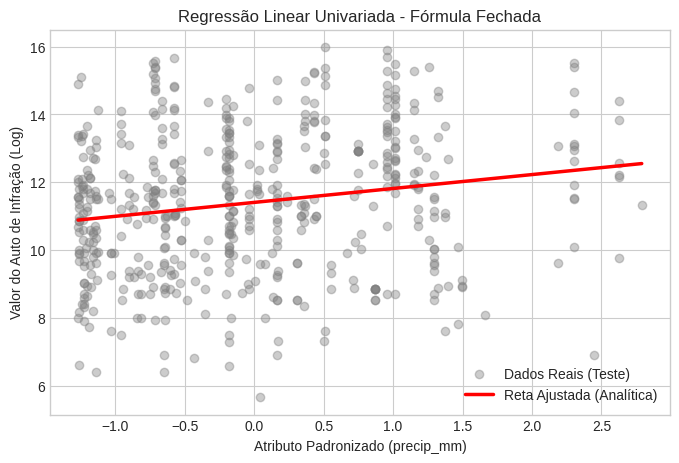

In [216]:
#CÉLULA 3
nomes_colunas = list(X_df.columns)
idx_melhor = (
    nomes_colunas.index('precip_mm') if 'precip_mm' in nomes_colunas else 0
)

x_uni_train = X_train[:, idx_melhor]
x_uni_test = X_test[:, idx_melhor]


def regressao_univariada_analitica(x, y):
  x_bar, y_bar = np.mean(x), np.mean(y)
  den = np.sum((x - x_bar) ** 2)
  if den == 0:
    return y_bar, 0.0
  w1 = np.sum((x - x_bar) * (y - y_bar)) / den
  w0 = y_bar - w1 * x_bar
  return w0, w1


w0_uni, w1_uni = regressao_univariada_analitica(x_uni_train, y_reg_train)
y_pred_uni = w0_uni + w1_uni * x_uni_test

ss_res = np.sum((y_reg_test - y_pred_uni) ** 2)
ss_tot = np.sum((y_reg_test - np.mean(y_reg_test)) ** 2)
r2_uni = 1 - (ss_res / ss_tot)

print(
    f'Atributo Selecionado: {nomes_colunas[idx_melhor]} (Índice: {idx_melhor})'
)
print(f'R² Regressao Univariada (Do Zero): {r2_uni:.4f}')

idx_ordem = np.argsort(x_uni_test)
plt.figure(figsize=(8, 5))
plt.scatter(
    x_uni_test, y_reg_test, alpha=0.4, color='gray', label='Dados Reais (Teste)'
)
plt.plot(
    x_uni_test[idx_ordem],
    y_pred_uni[idx_ordem],
    color='red',
    linewidth=2.5,
    label='Reta Ajustada (Analítica)',
)
plt.xlabel(f'Atributo Padronizado ({nomes_colunas[idx_melhor]})')
plt.ylabel('Valor do Auto de Infração (Log)')
plt.title('Regressão Linear Univariada - Fórmula Fechada')
plt.legend()
plt.savefig('grafico_regressao_simples.png', dpi=300, bbox_inches='tight')
plt.show()

R² Regressao Multivariada (Do Zero): 0.2672


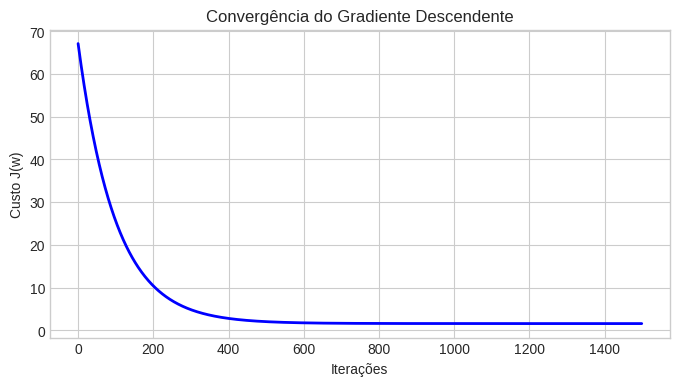

In [217]:
#CÉLULA 4
std_colunas = np.std(X_train, axis=0)
colunas_validas = np.where(std_colunas > 1e-8)[0]

X_train_clean = X_train[:, colunas_validas]
X_test_clean = X_test[:, colunas_validas]

X_train_b = np.c_[np.ones(X_train_clean.shape[0]), X_train_clean]
X_test_b = np.c_[np.ones(X_test_clean.shape[0]), X_test_clean]


def regressao_multivariada_analitica(X, y):
  return np.linalg.pinv(X.T @ X) @ X.T @ y


def gradiente_descendente(X, y, alpha=0.005, num_iter=1500):
  N, d = X.shape
  w = np.zeros(d)
  historico_custo = []
  for _ in range(num_iter):
    pred = X @ w
    erro = pred - y
    custo = (1 / (2 * N)) * np.sum(erro**2)
    historico_custo.append(custo)
    grad = (X.T @ erro) / N
    w = w - alpha * grad
  return w, historico_custo


w_multi = regressao_multivariada_analitica(X_train_b, y_reg_train)
_, historico_custo = gradiente_descendente(
    X_train_b, y_reg_train, alpha=0.005, num_iter=1500
)

y_pred_multi = X_test_b @ w_multi

ss_res_m = np.sum((y_reg_test - y_pred_multi) ** 2)
ss_tot_m = np.sum((y_reg_test - np.mean(y_reg_test)) ** 2)
r2_multi = 1 - (ss_res_m / ss_tot_m)

print(f'R² Regressao Multivariada (Do Zero): {r2_multi:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(historico_custo, color='blue', linewidth=2)
plt.xlabel('Iterações')
plt.ylabel('Custo J(w)')
plt.title('Convergência do Gradiente Descendente')
plt.savefig('grafico_curva_custo.png', dpi=300, bbox_inches='tight')
plt.show()

Lambda Ótimo: 0.0100 | R² Ridge (Do Zero): 0.2672


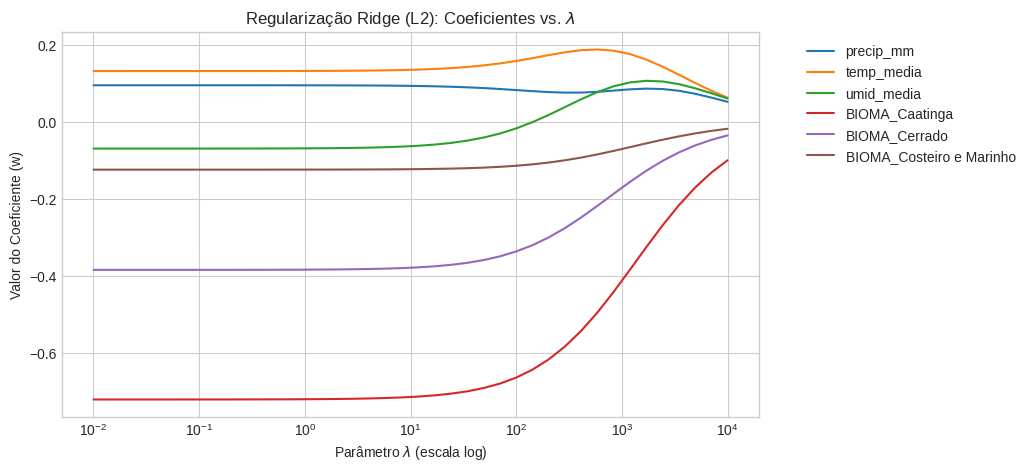

In [218]:
#CÉLULA 5
def ridge_analitico(X, y, lmbda):
  d = X.shape[1]
  I = np.eye(d)
  I[0, 0] = 0
  return np.linalg.pinv(X.T @ X + lmbda * I) @ X.T @ y


lambdas = np.logspace(-2, 4, 40)
coefs_ridge = []
r2_ridge_lista = []

for lmb in lambdas:
  w_r = ridge_analitico(X_train_b, y_reg_train, lmb)
  coefs_ridge.append(w_r[1:])
  y_p = X_test_b @ w_r

  ss_res_r = np.sum((y_reg_test - y_p) ** 2)
  ss_tot_r = np.sum((y_reg_test - np.mean(y_reg_test)) ** 2)
  r2_ridge_lista.append(1 - (ss_res_r / ss_tot_r))

coefs_ridge = np.array(coefs_ridge)
idx_opt = np.argmax(r2_ridge_lista)
lmbda_otimo = lambdas[idx_opt]
r2_ridge_opt = r2_ridge_lista[idx_opt]

print(
    f'Lambda Ótimo: {lmbda_otimo:.4f} | R² Ridge (Do Zero): {r2_ridge_opt:.4f}'
)

plt.figure(figsize=(9, 5))
colunas_nomes = X_df.columns[colunas_validas]
for i in range(min(6, coefs_ridge.shape[1])):
  plt.plot(lambdas, coefs_ridge[:, i], label=f'{colunas_nomes[i]}')

plt.xscale('log')
# Adicionado o prefixo 'r' para strings raw (LaTeX limpo)
plt.xlabel(r'Parâmetro $\lambda$ (escala log)')
plt.ylabel('Valor do Coeficiente (w)')
plt.title(r'Regularização Ridge (L2): Coeficientes vs. $\lambda$')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('grafico_ridge_coeficientes.png', dpi=300, bbox_inches='tight')
plt.show()

In [219]:
#CÉLULA 6
def sigmoide(z):
  z_clipped = np.clip(z, -250, 250)
  return 1 / (1 + np.exp(-z_clipped))


def regressao_logistica_fit(X, y, alpha=0.05, num_iter=3000):
  N, d = X.shape
  w = np.zeros(d)
  for _ in range(num_iter):
    prob = sigmoide(X @ w)
    grad = (X.T @ (prob - y)) / N
    w = w - alpha * grad
  return w


w_log = regressao_logistica_fit(
    X_train_b, y_cls_train, alpha=0.05, num_iter=3000
)
prob_test = sigmoide(X_test_b @ w_log)
y_pred_log = (prob_test >= 0.5).astype(int)

acc_log_zero = accuracy_score(y_cls_test, y_pred_log)
print(f'Acurácia Regressão Logística (Do Zero): {acc_log_zero:.2%}')

Acurácia Regressão Logística (Do Zero): 70.94%


In [220]:
#CÉLULA 7
# 1. Modelos equivalentes via Scikit-Learn
sk_uni = LinearRegression().fit(x_uni_train.reshape(-1, 1), y_reg_train)
r2_uni_sk = sk_uni.score(x_uni_test.reshape(-1, 1), y_reg_test)

sk_multi = LinearRegression().fit(X_train_clean, y_reg_train)
r2_multi_sk = sk_multi.score(X_test_clean, y_reg_test)

sk_ridge = Ridge(alpha=lmbda_otimo).fit(X_train_clean, y_reg_train)
r2_ridge_sk = sk_ridge.score(X_test_clean, y_reg_test)

sk_log = LogisticRegression(max_iter=1000).fit(X_train_clean, y_cls_train)
acc_log_sk = sk_log.score(X_test_clean, y_cls_test)

# 2. DataFrame da Tabela Comparativa Final
tabela = pd.DataFrame({
    'Modelo': [
        'Regressão Linear Simples',
        'Regressão Multivariada',
        'Ridge (L2)',
        'Regressão Logística',
    ],
    'Gabarito Esperado (Teórico)': [
        '0,55 - 0,65',
        '0,70 - 0,80',
        '0,72 - 0,82',
        '78 - 85%',
    ],
    'Do Zero (Real)': [
        f'{r2_uni:.4f}',
        f'{r2_multi:.4f}',
        f'{r2_ridge_opt:.4f}',
        f'{acc_log_zero:.2%}',
    ],
    'Scikit-Learn (Real)': [
        f'{r2_uni_sk:.4f}',
        f'{r2_multi_sk:.4f}',
        f'{r2_ridge_sk:.4f}',
        f'{acc_log_sk:.2%}',
    ],
})

print('\n=== TABELA FINAL DE RESULTADOS DA ETAPA 2 ===')
print(tabela.to_string(index=False))


=== TABELA FINAL DE RESULTADOS DA ETAPA 2 ===
                  Modelo Gabarito Esperado (Teórico) Do Zero (Real) Scikit-Learn (Real)
Regressão Linear Simples                 0,55 - 0,65         0.0363              0.0363
  Regressão Multivariada                 0,70 - 0,80         0.2672              0.2672
              Ridge (L2)                 0,72 - 0,82         0.2672              0.2672
     Regressão Logística                    78 - 85%         70.94%              70.94%
